# 11 報告用圖表

把前面 notebook 的結果畫成報告與海報用的圖。所有數字都從 `data/` 裡存好的結果或重新估計而來，不手打。
色彩規則：家庭＝藍、工作＝橘、經濟＝綠、健康＝灰，全報告一致。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.patches as mpatches
from psfd_utils import *
plt = setup_plot()
import matplotlib as mpl
mpl.rcParams.update({"font.size": 9.5, "axes.titlesize": 10.5, "savefig.dpi": 300})
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
shap = pd.read_csv(DERIVED / "shapley_recipe.csv", index_col=0).shapley
trend = pd.read_csv(DERIVED / "weights_trend_2007_2024.csv")
cv = pd.read_csv(DERIVED / "cv_models_2022.csv")
cl = pd.read_csv(DERIVED / "cross_lagged.csv")
ev = pd.read_csv(DERIVED / "event_studies.csv")
INK, INK2 = PALETTE["ink"], PALETTE["ink2"]

## R1 幸福配方（Shapley 分解）— 封面用的一條長條

PosixPath('figures/R1_recipe_bar.png')

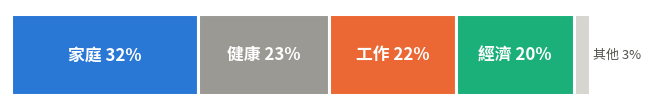

In [2]:
share = (shap / shap.sum() * 100)
order = [("家庭", C_FAMILY), ("健康", C_HEALTH), ("工作", C_WORK), ("經濟", C_ECON), ("人口與年份", "#d6d5d0")]
fig, ax = plt.subplots(figsize=(7.2, 1.05))
left = 0
for nm, col in order:
    v = share[nm]
    ax.barh(0, v, left=left, color=col, height=0.62, edgecolor="white", linewidth=2)
    if v > 6:
        ax.text(left + v / 2, 0, f"{nm} {v:.0f}%", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += v
ax.text(left + 0.5, 0, "其他 3%", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, 106); ax.axis("off")
savefig(fig, "R1_recipe_bar")

## R2 18 年趨勢

PosixPath('figures/R2_trend.png')

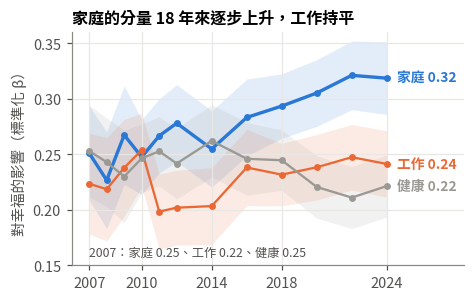

In [3]:
fig, ax = plt.subplots(figsize=(4.6, 2.75))
for name, col in [("家庭", C_FAMILY), ("工作", C_WORK), ("健康", C_HEALTH)]:
    t = trend[trend.領域 == name]
    ax.fill_between(t.year, t.lo, t.hi, color=col, alpha=0.13, lw=0)
    ax.plot(t.year, t.beta, marker="o", ms=3.5, color=col, lw=2.2 if name == "家庭" else 1.5)
    ax.text(2024.6, t.beta.iloc[-1], f"{name} {t.beta.iloc[-1]:.2f}", va="center", color=col, fontsize=9, fontweight="bold")
ax.set_xlim(2006, 2028.4); ax.set_ylim(0.15, 0.36)
ax.set_xticks([2007, 2010, 2014, 2018, 2024], ["2007", "2010", "2014", "2018", "2024"])
ax.text(2007, 0.158, "2007：家庭 0.25、工作 0.22、健康 0.25", fontsize=8, color=INK2)
ax.set_ylabel("對幸福的影響（標準化 β）")
ax.set_title("家庭的分量 18 年來逐步上升，工作持平", loc="left")
savefig(fig, "R2_trend")

## R3 個人權重：「說重視什麼」vs「人生階段」vs 預測力

In [4]:
emp = main[main.employed == 1].dropna(subset=["swb", "jobsat", "famsat", "econsat", "health", "age", "female"]).copy()
for c in ["swb", "jobsat", "famsat", "econsat", "health"]:
    emp[c + "_z"] = emp.groupby("year")[c].transform(z)
F = "swb_z ~ jobsat_z + famsat_z + econsat_z + health_z + age + I(age**2) + web"
rng = np.random.default_rng(0)


def w_boot(g, f=F, B=300):
    m = smf.ols(f, g).fit(); w0 = m.params.famsat_z / (m.params.famsat_z + m.params.jobsat_z)
    X = m.model.exog; y = m.model.endog; ij, iF = m.model.exog_names.index("jobsat_z"), m.model.exog_names.index("famsat_z")
    ws = []
    for _ in range(B):
        idx = rng.integers(0, len(y), len(y))
        b = np.linalg.lstsq(X[idx], y[idx], rcond=None)[0]
        ws.append(b[iF] / (b[iF] + b[ij]))
    return w0, np.percentile(ws, 2.5), np.percentile(ws, 97.5)


d22 = emp[(emp.year == 2022)].dropna(subset=["fam_importance"]).copy()
d22["q"] = pd.qcut(d22.fam_importance, 5, labels=False, duplicates="drop") + 1
imp_rows = [dict(g=q, **dict(zip(["w", "lo", "hi"], w_boot(g, F + " + female")))) for q, g in d22.groupby("q")]
imp_w = pd.DataFrame(imp_rows)

e = emp.dropna(subset=["has_kids"]).copy()
e["stage"] = np.select([e.has_kids == 0, e.kid_under6 == 1, e.youngest_child_age < 18, e.has_kids == 1],
                       ["沒有\n子女", "最小\n0–5 歲", "最小\n6–17 歲", "子女\n已成年"], default=None)
st_rows = []
for (st, f), g in e.dropna(subset=["stage"]).groupby(["stage", "female"]):
    w0, lo, hi = w_boot(g, F + " + C(year)")
    st_rows.append(dict(stage=st, sex="媽媽" if f == 1 else "爸爸", w=w0, lo=lo, hi=hi, N=len(g)))
st_w = pd.DataFrame(st_rows)
st_w["sex"] = np.where(st_w.stage == "沒有\n子女", np.where(st_w.sex == "媽媽", "女性", "男性"), st_w.sex)
imp_w.round(3), st_w.round(3)

(   g      w     lo     hi
 0  1  0.467  0.348  0.566
 1  2  0.570  0.499  0.664
 2  3  0.643  0.534  0.798
 3  4  0.621  0.506  0.732
 4  5  0.678  0.528  0.816,
         stage sex      w     lo     hi     N
 0     子女\n已成年  爸爸  0.655  0.553  0.772   884
 1     子女\n已成年  媽媽  0.776  0.634  0.954   775
 2   最小\n0–5 歲  爸爸  0.640  0.561  0.721  1384
 3   最小\n0–5 歲  媽媽  0.699  0.611  0.797   980
 4  最小\n6–17 歲  爸爸  0.538  0.469  0.619  1638
 5  最小\n6–17 歲  媽媽  0.708  0.625  0.804  1378
 6      沒有\n子女  男性  0.530  0.475  0.586  3496
 7      沒有\n子女  女性  0.509  0.451  0.576  2544)

PosixPath('figures/R3_personal_weights.png')

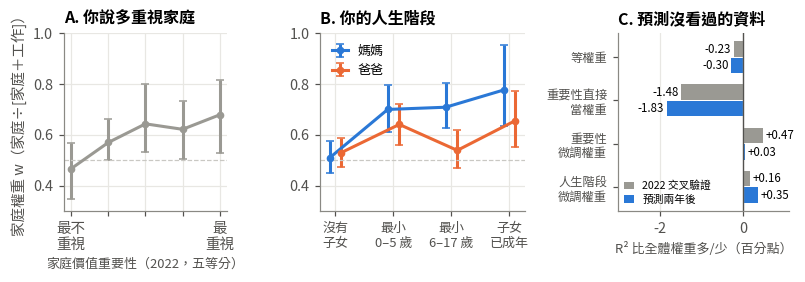

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.65), gridspec_kw={"width_ratios": [1, 1.25, 1.05]})
ax = axes[0]
ax.errorbar(imp_w.g, imp_w.w, yerr=[imp_w.w - imp_w.lo, imp_w.hi - imp_w.w], color=PALETTE["grey"], marker="o", capsize=2.5, ms=4)
ax.axhline(0.5, color="#c9c8c3", ls="--", lw=0.8)
ax.set_xticks([1, 2, 3, 4, 5], ["最不\n重視", "", "", "", "最\n重視"]); ax.set_ylim(0.3, 1.0)
ax.set_ylabel("家庭權重 w（家庭÷[家庭＋工作]）")
ax.set_title("A. 你說多重視家庭", loc="left")
ax.set_xlabel("家庭價值重要性（2022，五等分）", fontsize=8.5)
ax = axes[1]
stages = ["沒有\n子女", "最小\n0–5 歲", "最小\n6–17 歲", "子女\n已成年"]
for sx, col, off in [("媽媽", C_FAMILY, -0.1), ("爸爸", C_WORK, 0.1)]:
    t = st_w[st_w.sex.isin([sx, "女性" if sx == "媽媽" else "男性"])].set_index("stage").loc[stages]
    ax.errorbar(np.arange(4) + off, t.w, yerr=[t.w - t.lo, t.hi - t.w], fmt="o-", color=col, capsize=2.5, ms=4, label=sx if sx else None)
ax.axhline(0.5, color="#c9c8c3", ls="--", lw=0.8)
ax.set_xticks(range(4), stages, fontsize=8.5); ax.set_ylim(0.3, 1.0)
ax.legend(loc="upper left", fontsize=8.5, handlelength=1.2)
ax.set_title("B. 你的人生階段", loc="left")
ax = axes[2]
oot = pd.read_csv(DERIVED / "oot_2024_models.csv")
lab = {"M0 等權重": "等權重", "M_原構想（重要性百分位當權重）": "重要性直接\n當權重", "M2 重要性調節": "重要性\n微調權重", "M3 人生階段調節": "人生階段\n微調權重"}
base_cv = cv.set_index("模型").CV_R2["M1 全體權重"]; base_oot = oot.set_index("模型").預測2024_R2["M1 全體權重"]
ms = list(lab)
d_cv = [(cv.set_index("模型").CV_R2[m] - base_cv) * 100 for m in ms]
d_oot = [(oot.set_index("模型").預測2024_R2[m] - base_oot) * 100 for m in ms]
y = np.arange(len(ms))
ax.barh(y - 0.19, d_cv, height=0.36, color=PALETTE["grey"], label="2022 交叉驗證")
ax.barh(y + 0.19, d_oot, height=0.36, color=C_FAMILY, label="預測兩年後")
for yy, v in zip(y - 0.19, d_cv): ax.text(v + (0.06 if v >= 0 else -0.06), yy, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
for yy, v in zip(y + 0.19, d_oot): ax.text(v + (0.06 if v >= 0 else -0.06), yy, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
ax.axvline(0, color=INK2, lw=0.9)
ax.set_yticks(y, [lab[m] for m in ms], fontsize=8); ax.invert_yaxis(); ax.set_xlim(-3.0, 1.1)
ax.grid(axis="y", visible=False); ax.set_xlabel("R² 比全體權重多/少（百分點）", fontsize=8.5)
ax.legend(fontsize=7, loc="lower left", handlelength=0.9, borderaxespad=0.2, labelspacing=0.3)
ax.set_title("C. 預測沒看過的資料", loc="left")
fig.tight_layout(w_pad=1.2)
savefig(fig, "R3_personal_weights")

## R4 因果方向（交叉延宕）與人生事件

PosixPath('figures/R4_causality_events.png')

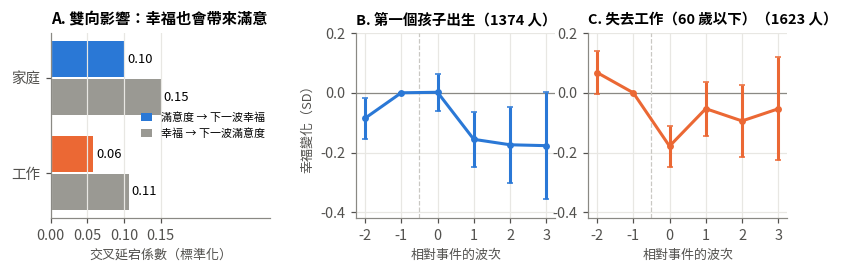

In [6]:
g = cl[cl.版本 == "一般"].set_index(["前一波", "結果"]).coef
gw = cl[cl.版本 == "個人中心化"].set_index(["前一波", "結果"]).coef
fig = plt.figure(figsize=(7.4, 2.55))
axd = fig.add_axes([0.075, 0.2, 0.27, 0.66])
labels_ = ["家庭", "工作"]
fwd = [g[("家庭滿意", "幸福")], g[("工作滿意", "幸福")]]
bwd = [g[("幸福", "家庭滿意")], g[("幸福", "工作滿意")]]
yy = np.arange(2)
axd.barh(yy - 0.2, fwd, height=0.38, color=[C_FAMILY, C_WORK], label="滿意度 → 下一波幸福")
axd.barh(yy + 0.2, bwd, height=0.38, color=PALETTE["grey"], label="幸福 → 下一波滿意度")
for y_, v in zip(yy - 0.2, fwd): axd.text(v + 0.004, y_, f"{v:.2f}", va="center", fontsize=8.5)
for y_, v in zip(yy + 0.2, bwd): axd.text(v + 0.004, y_, f"{v:.2f}", va="center", fontsize=8.5)
axd.set_yticks(yy, labels_); axd.invert_yaxis(); axd.set_xlim(0, 0.30); axd.grid(axis="y", visible=False)
axd.set_xticks([0, 0.05, 0.10, 0.15])
axd.set_xlabel("交叉延宕係數（標準化）", fontsize=8.5)
axd.legend(fontsize=7.2, loc="center right", handlelength=1, borderaxespad=0.1)
axd.set_title("A. 雙向影響：幸福也會帶來滿意", loc="left", fontsize=10)
for k, (nm, col) in enumerate([("第一個孩子出生", C_FAMILY), ("失去工作（60 歲以下）", C_WORK)]):
    ax = fig.add_axes([0.45 + k * 0.285, 0.2, 0.245, 0.66])
    t = ev[ev.事件 == nm].sort_values("et")
    ax.axhline(0, color="#8a8984", lw=0.8); ax.axvline(-0.5, color="#c9c8c3", lw=0.8, ls="--")
    ax.errorbar(t.et, t.coef, yerr=[t.coef - t.lo, t.hi - t.coef], marker="o", ms=3.5, color=col, capsize=2)
    ax.set_xticks(range(-2, 4)); ax.set_ylim(-0.42, 0.2)
    ax.set_xlabel("相對事件的波次", fontsize=8.5)
    if k == 0: ax.set_ylabel("幸福變化（SD）", fontsize=8.5)
    ax.set_title(("B. " if k == 0 else "C. ") + nm + f"（{int(t.人數.iloc[0])} 人）", loc="left", fontsize=9.5)
savefig(fig, "R4_causality_events")

## R5 成就 ≠ 滿足：家庭生活很不滿意時，已婚者並不比單身快樂

PosixPath('figures/R5_marriage.png')

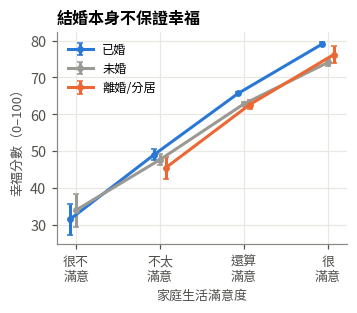

In [7]:
q = main.dropna(subset=["swb", "famsat", "marital"]).copy()
q["mg"] = q.marital.map({"married": "已婚", "never": "未婚", "divorced": "離婚/分居", "separated": "離婚/分居", "widowed": "喪偶"})
fig, ax = plt.subplots(figsize=(3.4, 2.5))
for mg, col in [("已婚", C_FAMILY), ("未婚", PALETTE["grey"]), ("離婚/分居", C_WORK)]:
    t = q[q.mg == mg].groupby("famsat").swb.agg(["mean", "count", "std"]); t = t[t["count"] >= 30]
    ax.errorbar(t.index + {"已婚": -0.07, "未婚": 0, "離婚/分居": 0.07}[mg], t["mean"], yerr=1.96 * t["std"] / np.sqrt(t["count"]), marker="o", ms=3.5, color=col, label=mg, capsize=2)
ax.set_xticks([1, 2, 3, 4], ["很不\n滿意", "不太\n滿意", "還算\n滿意", "很\n滿意"], fontsize=8.5)
ax.set_xlabel("家庭生活滿意度", fontsize=8.5); ax.set_ylabel("幸福分數（0–100）", fontsize=8.5)
ax.legend(fontsize=8, loc="upper left"); ax.set_title("結婚本身不保證幸福", loc="left")
savefig(fig, "R5_marriage")